In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.inspection import permutation_importance

In [3]:
RANDOM_STATE = 42   # supaya hasil selalu sama setiap dijalankan
sns.set_theme(style='whitegrid')

In [4]:
df_raw = pd.read_csv('original.csv')



In [5]:
print('Dimensi (baris, kolom):', df_raw.shape)
df_raw.info()

Dimensi (baris, kolom): (87, 22)
<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             80 non-null     float64
 1   Age                                80 non-null     float64
 2   POLAR4 Quintile                    80 non-null     float64
 3   POLAR3 Quintile                    80 non-null     float64
 4   Adult HE 2001 Quintile             80 non-null     float64
 5   Adult HE 2011 Quintile             80 non-null     float64
 6   TUNDRA MSOA Quintile               80 non-null     float64
 7   TUNDRA LSOA Quintile               80 non-null     float64
 8   Gaps GCSE Quintile                 80 non-null     float64
 9   Gaps GCSE Ethnicity Quintile       80 non-null     float64
 10  Uni Connect target ward            80 non-null     float64
 11  attending from home?               80 

In [6]:
df_raw.head()

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,...,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended,"label (fail=1, pass=0)",Unnamed: 20,Unnamed: 21
0,0.0,38.0,5.0,5.0,4.0,5.0,4.0,4.0,5.0,5.0,...,13.333806,19.0,7.41,0.620767,3.0,9.0,25.000000,1.0,NaN,NaN
1,0.0,22.0,4.0,2.0,1.0,3.0,4.0,4.0,4.0,5.0,...,15.844126,1.0,0.03,0.002513,0.0,12.0,0.000000,1.0,NaN,NaN
2,0.0,21.0,4.0,5.0,4.0,5.0,4.0,4.0,5.0,5.0,...,17.706573,25.0,6.14,0.514374,5.0,7.0,41.666667,1.0,NaN,NaN
3,0.0,25.0,5.0,4.0,3.0,4.0,3.0,3.0,5.0,5.0,...,17.327498,3.0,0.16,0.013404,0.0,12.0,0.000000,1.0,NaN,NaN
4,0.0,20.0,5.0,4.0,3.0,4.0,3.0,3.0,4.0,4.0,...,0.000000,25.0,4.03,0.337610,11.0,1.0,91.666667,1.0,NaN,NaN


In [7]:
df = df_raw.copy()
df.columns = df.columns.str.strip()          # rapikan spasi di nama kolom
df = df.dropna(axis=1, how='all')            # buang kolom yang kosong semua
df = df.dropna(axis=0, how='all')            # buang baris yang kosong semua


In [8]:
# Cari nama kolom label (yang diawali kata 'label')
LABEL = [c for c in df.columns if c.lower().startswith('label')][0]


In [9]:
kelompok_fitur = {
    'Demografi': ['Gender', 'Age'],
    'Latar belakang wilayah': ['POLAR4 Quintile', 'POLAR3 Quintile', 'Adult HE 2001 Quintile',
                               'Adult HE 2011 Quintile', 'TUNDRA MSOA Quintile', 'TUNDRA LSOA Quintile',
                               'Gaps GCSE Quintile', 'Gaps GCSE Ethnicity Quintile', 'Uni Connect target ward'],
    'Keterlibatan belajar': ['attending from home?', 'distance to university (km)',
                             'Count of Module Area Logins', 'Total Hours in Module Area',
                             '% of Average Hours in Module Area'],
    'Kehadiran': ['# of presence', '# of Absence', 'Percent Attended'],
}
for nama, kolom in kelompok_fitur.items():
    print(nama, '->', len(kolom), 'fitur')

Demografi -> 2 fitur
Latar belakang wilayah -> 9 fitur
Keterlibatan belajar -> 5 fitur
Kehadiran -> 3 fitur


In [10]:
print()
print('Label :', LABEL)
print('Jumlah fitur:', df.shape[1] - 1)


Label : label (fail=1, pass=0)
Jumlah fitur: 19


In [11]:
jumlah = df[LABEL].value_counts().sort_index()
persen = df[LABEL].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({'jumlah': jumlah, 'persen': persen.round(1)}))


                        jumlah  persen
label (fail=1, pass=0)                
0.0                         68    85.0
1.0                         12    15.0


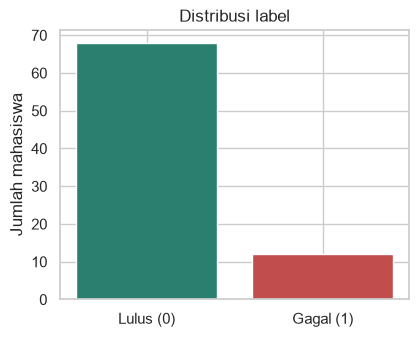

In [12]:
plt.figure(figsize=(4.5, 3.5))
plt.bar(['Lulus (0)', 'Gagal (1)'], jumlah.values, color=['#2a7f6e', '#c24d4d'])
plt.ylabel('Jumlah mahasiswa')
plt.title('Distribusi label')
plt.show()

In [13]:
print('Ukuran data setelah baris/kolom kosong dibuang:', df.shape)
print()
print('Nilai hilang per kolom:')
hilang = df.isna().sum()
print(hilang[hilang > 0])
print()
print('Baris duplikat:', df.duplicated().sum())

Ukuran data setelah baris/kolom kosong dibuang: (80, 20)

Nilai hilang per kolom:
# of Absence    2
dtype: int64

Baris duplikat: 0


In [14]:
# Nilai hilang pada '# of Absence' diisi: absen = 12 pertemuan - hadir
df['# of Absence'] = df['# of Absence'].fillna(12 - df['# of presence'])

# Buang duplikat dan pastikan label berupa bilangan bulat
df = df.drop_duplicates().dropna(subset=[LABEL]).reset_index(drop=True)
df[LABEL] = df[LABEL].astype(int)


In [15]:
print('Ukuran data bersih:', df.shape)
print('Sisa nilai hilang :', df.isna().sum().sum())

Ukuran data bersih: (80, 20)
Sisa nilai hilang : 0


In [16]:
kolom_numerik = ['Age', 'distance to university (km)', 'Count of Module Area Logins',
                 'Total Hours in Module Area', '% of Average Hours in Module Area', 'Percent Attended']


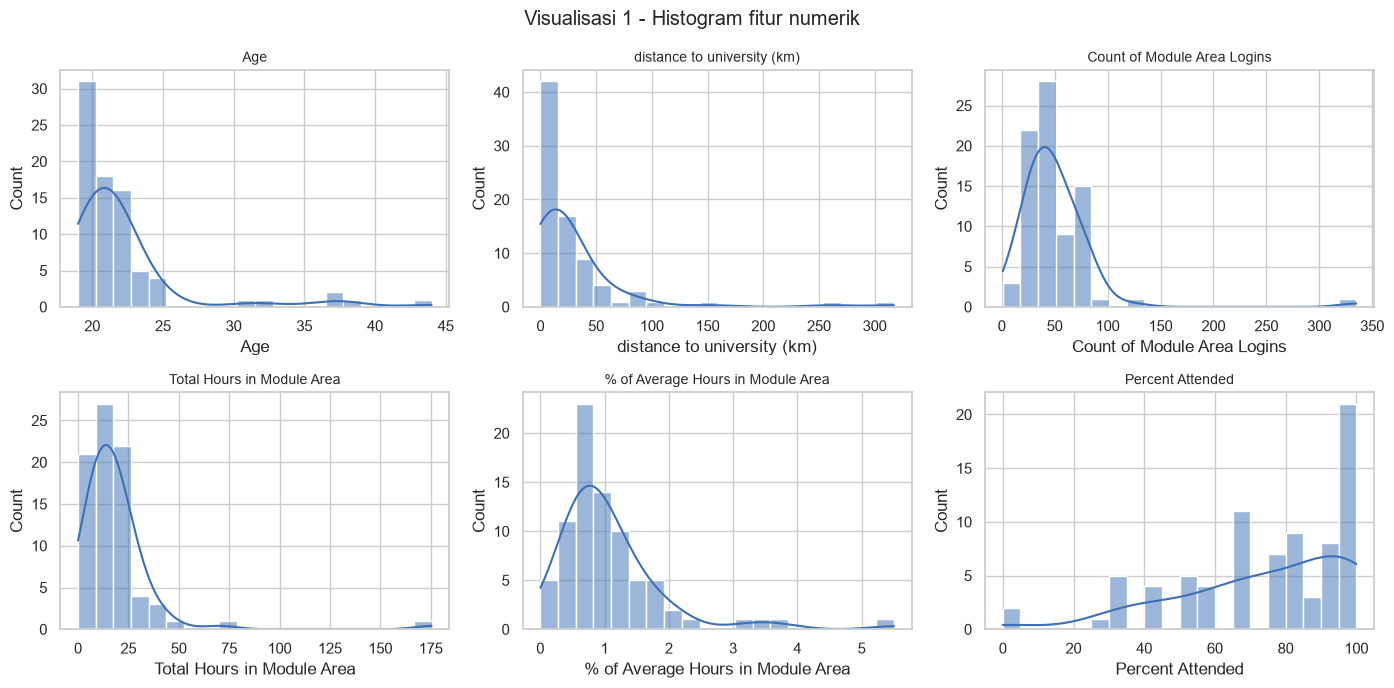

In [17]:
# Visualisasi 1: histogram
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, kolom in zip(axes.ravel(), kolom_numerik):
    sns.histplot(df[kolom], bins=20, kde=True, ax=ax, color='#3b6fb6')
    ax.set_title(kolom, fontsize=10)
plt.suptitle('Visualisasi 1 - Histogram fitur numerik')
plt.tight_layout()
plt.show()

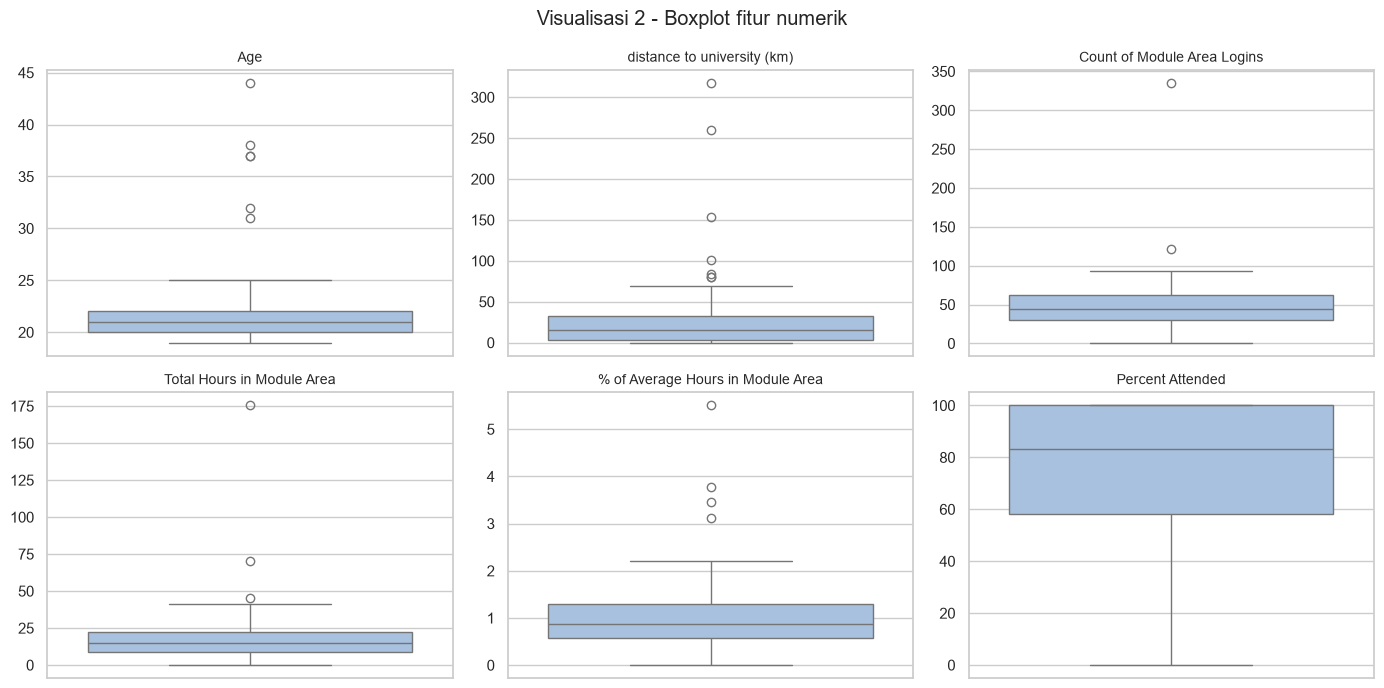

In [18]:
# Visualisasi 2: boxplot (untuk melihat outlier)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, kolom in zip(axes.ravel(), kolom_numerik):
    sns.boxplot(y=df[kolom], ax=ax, color='#9ec1e8')
    ax.set_title(kolom, fontsize=10)
    ax.set_ylabel('')
plt.suptitle('Visualisasi 2 - Boxplot fitur numerik')
plt.tight_layout()
plt.show()

In [19]:
kolom_banding = ['Percent Attended', '# of Absence', 'Count of Module Area Logins',
                 'Total Hours in Module Area', 'distance to university (km)', '% of Average Hours in Module Area']

C:\Users\ACER\AppData\Local\Temp\ipykernel_34620\3839202786.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=LABEL, y=kolom, ax=ax, palette=['#2a7f6e', '#c24d4d'])
C:\Users\ACER\AppData\Local\Temp\ipykernel_34620\3839202786.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Lulus (0)', 'Gagal (1)'])
C:\Users\ACER\AppData\Local\Temp\ipykernel_34620\3839202786.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=LABEL, y=kolom, ax=ax, palette=['#2a7f6e', '#c24d4d'])
C:\Users\ACER\AppData\Local\Temp\ipykernel_34620\3839202786.py:

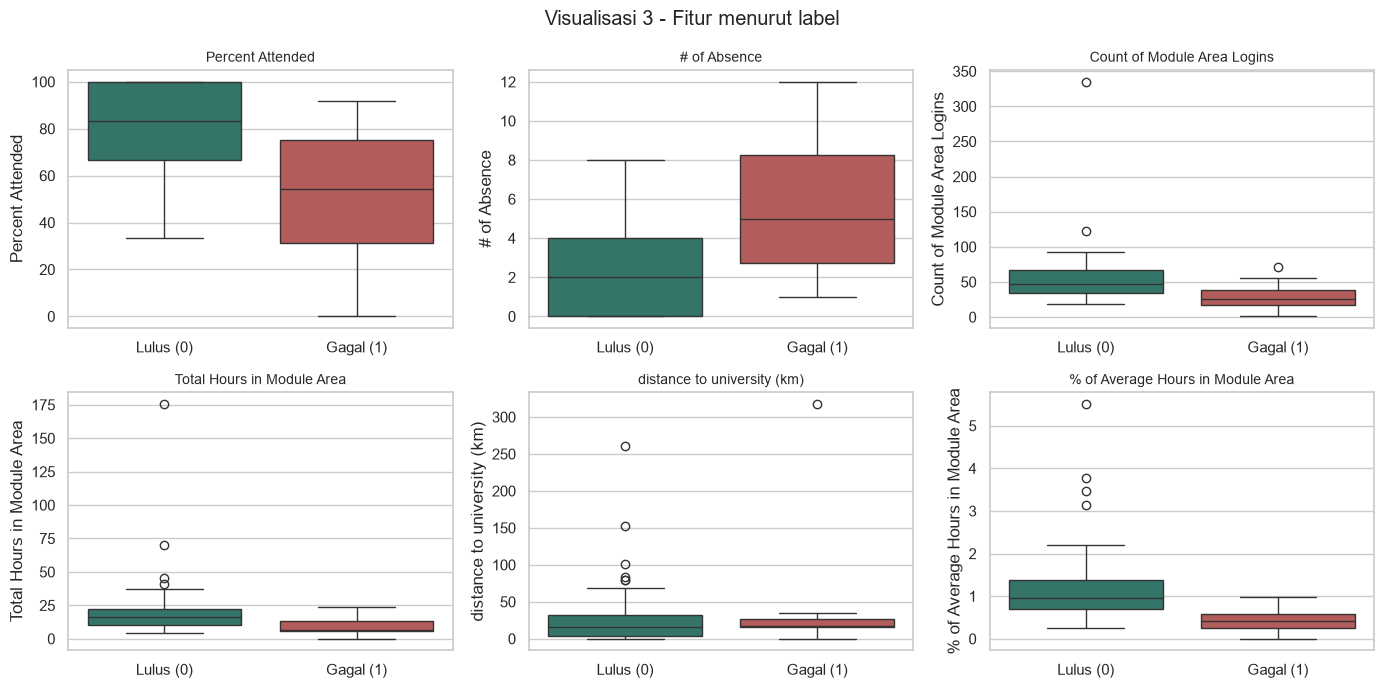

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, kolom in zip(axes.ravel(), kolom_banding):
    sns.boxplot(data=df, x=LABEL, y=kolom, ax=ax, palette=['#2a7f6e', '#c24d4d'])
    ax.set_xticklabels(['Lulus (0)', 'Gagal (1)'])
    ax.set_xlabel('')
    ax.set_title(kolom, fontsize=10)
plt.suptitle('Visualisasi 3 - Fitur menurut label')
plt.tight_layout()
plt.show()

In [21]:
# Rata-rata tiap fitur per kelompok
df.groupby(LABEL)[kolom_banding].mean().round(2)

,Percent Attended,# of Absence,Count of Module Area Logins,Total Hours in Module Area,distance to university (km),% of Average Hours in Module Area
"label (fail=1, pass=0)",,,,,,
0,78.55,2.44,54.01,20.32,26.86,1.19
1,50.69,5.75,28.42,9.02,42.72,0.43


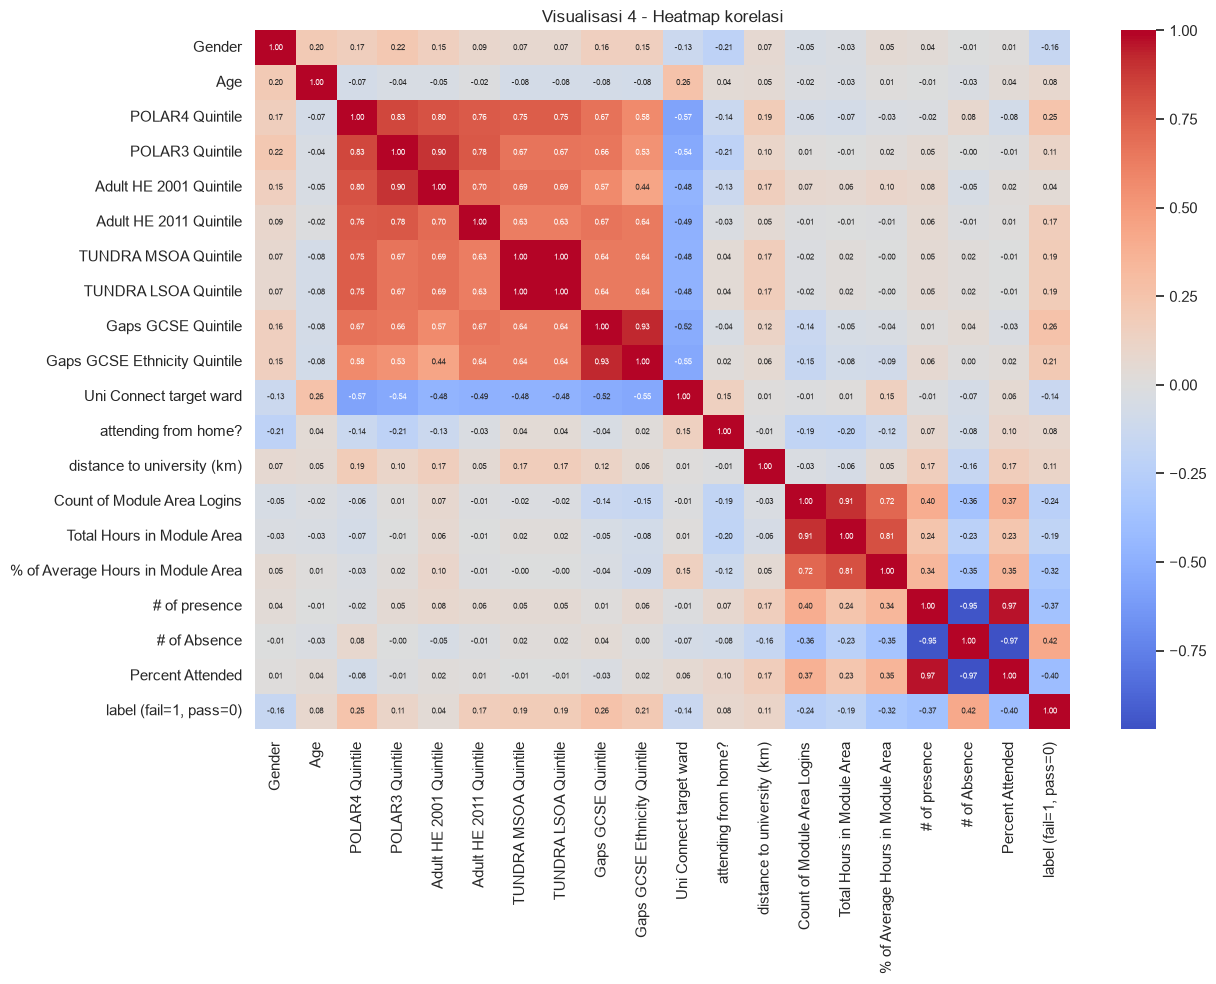

In [22]:
# Visualisasi 4: heatmap korelasi
korelasi = df.corr(numeric_only=True)

plt.figure(figsize=(13, 10))
sns.heatmap(korelasi, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 6})
plt.title('Visualisasi 4 - Heatmap korelasi')
plt.tight_layout()
plt.show()


In [23]:
print('Korelasi fitur dengan label (8 terbesar):')
print(korelasi[LABEL].drop(LABEL).abs().sort_values(ascending=False).head(8).round(2))

Korelasi fitur dengan label (8 terbesar):
# of Absence                         0.42
Percent Attended                     0.40
# of presence                        0.37
% of Average Hours in Module Area    0.32
Gaps GCSE Quintile                   0.26
POLAR4 Quintile                      0.25
Count of Module Area Logins          0.24
Gaps GCSE Ethnicity Quintile         0.21
Name: label (fail=1, pass=0), dtype: float64


In [24]:
# (a) Outlier dengan aturan IQR: nilai di luar Q1 - 1.5*IQR atau Q3 + 1.5*IQR
kolom_kontinu = ['Age', 'distance to university (km)', 'Count of Module Area Logins',
                 'Total Hours in Module Area', '% of Average Hours in Module Area']

In [25]:
for kolom in kolom_kontinu:
    q1 = df[kolom].quantile(0.25)
    q3 = df[kolom].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    n_outlier = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
    print(f'{kolom:38s} outlier: {n_outlier:2d}  (median {df[kolom].median():.1f}, maks {df[kolom].max():.1f})')

Age                                    outlier:  6  (median 21.0, maks 44.0)
distance to university (km)            outlier:  7  (median 15.7, maks 317.3)
Count of Module Area Logins            outlier:  2  (median 44.5, maks 335.0)
Total Hours in Module Area             outlier:  3  (median 14.8, maks 175.4)
% of Average Hours in Module Area      outlier:  4  (median 0.9, maks 5.5)


In [26]:
# (b) Nilai tidak wajar: kuintil seharusnya 1-5, jadi angka 0 mencurigakan
kolom_kuintil = [c for c in df.columns if 'Quintile' in c]
print()
print('Jumlah nilai 0 pada kolom kuintil:')
nol = (df[kolom_kuintil] == 0).sum()
print(nol[nol > 0])



Jumlah nilai 0 pada kolom kuintil:
Adult HE 2011 Quintile          2
TUNDRA MSOA Quintile            2
TUNDRA LSOA Quintile            2
Gaps GCSE Quintile              4
Gaps GCSE Ethnicity Quintile    4
dtype: int64


In [27]:
# (c) Rentang logis
print()
print('Percent Attended di luar 0-100:', ((df['Percent Attended'] < 0) | (df['Percent Attended'] > 100)).sum())
print('Jarak negatif                 :', (df['distance to university (km)'] < 0).sum())


Percent Attended di luar 0-100: 0
Jarak negatif                 : 0


In [28]:
# Fitur yang dibuang beserta alasannya
fitur_dibuang = {
    'TUNDRA LSOA Quintile': 'identik dengan TUNDRA MSOA Quintile (duplikat)',
    '# of presence': 'redundan: Percent Attended = # of presence / 12',
    '# of Absence': 'redundan: kebalikan dari # of presence',
    'Gender': 'fitur sensitif (etika) dan sangat timpang',
}
for nama, alasan in fitur_dibuang.items():
    print(f'{nama:22s} -> {alasan}')


TUNDRA LSOA Quintile   -> identik dengan TUNDRA MSOA Quintile (duplikat)
# of presence          -> redundan: Percent Attended = # of presence / 12
# of Absence           -> redundan: kebalikan dari # of presence
Gender                 -> fitur sensitif (etika) dan sangat timpang


In [29]:
print()
print('TUNDRA MSOA identik dengan LSOA?', df['TUNDRA MSOA Quintile'].equals(df['TUNDRA LSOA Quintile']))


TUNDRA MSOA identik dengan LSOA? True


In [30]:
# Fitur yang miring ke kanan -> ditransformasi log1p
fitur_miring = ['distance to university (km)', 'Count of Module Area Logins',
                'Total Hours in Module Area', '% of Average Hours in Module Area']

In [31]:
def siapkan_data(data):
    """Langkah pembersihan yang sama untuk data latih, data uji, dan data baru."""
    data = data.copy()
    data[kolom_kuintil] = data[kolom_kuintil].replace(0, np.nan)   # 0 pada kuintil dianggap hilang
    data[fitur_miring] = np.log1p(data[fitur_miring])              # redam outlier
    data = data.drop(columns=list(fitur_dibuang))                  # buang fitur redundan/sensitif
    return data

In [32]:
X = siapkan_data(df.drop(columns=[LABEL]))
y = df[LABEL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

In [33]:
print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)
print('Proporsi gagal -> semua: %.3f | latih: %.3f | uji: %.3f' % (y.mean(), y_train.mean(), y_test.mean()))

Data latih: (64, 15) | Data uji: (16, 15)
Proporsi gagal -> semua: 0.150 | latih: 0.156 | uji: 0.125


In [34]:
# Cari pasangan fitur dengan korelasi mutlak > 0.90 (hanya dari DATA LATIH)
korelasi_latih = X_train.corr().abs()
kolom_buang_korelasi = []
for i in range(len(korelasi_latih.columns)):
    for j in range(i + 1, len(korelasi_latih.columns)):
        if korelasi_latih.iloc[i, j] > 0.90:
            print('Korelasi tinggi:', korelasi_latih.columns[i], '&', korelasi_latih.columns[j])
            kolom_buang_korelasi.append(korelasi_latih.columns[j])

Korelasi tinggi: POLAR3 Quintile & Adult HE 2001 Quintile


In [35]:
X_train = X_train.drop(columns=kolom_buang_korelasi)
X_test = X_test.drop(columns=kolom_buang_korelasi)

In [36]:
FITUR_AKHIR = list(X_train.columns)
print()
print('Fitur tambahan yang dibuang:', kolom_buang_korelasi if kolom_buang_korelasi else 'tidak ada')
print(f'Fitur akhir ({len(FITUR_AKHIR)}):', FITUR_AKHIR)


Fitur tambahan yang dibuang: ['Adult HE 2001 Quintile']
Fitur akhir (14): ['Age', 'POLAR4 Quintile', 'POLAR3 Quintile', 'Adult HE 2011 Quintile', 'TUNDRA MSOA Quintile', 'Gaps GCSE Quintile', 'Gaps GCSE Ethnicity Quintile', 'Uni Connect target ward', 'attending from home?', 'distance to university (km)', 'Count of Module Area Logins', 'Total Hours in Module Area', '% of Average Hours in Module Area', 'Percent Attended']


In [37]:
# Tiap model = isi nilai hilang -> skala -> model
models = {
    'Logistic Regression': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
    'Decision Tree': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
        DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, class_weight='balanced', random_state=RANDOM_STATE)),
    'Random Forest': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced_subsample', random_state=RANDOM_STATE)),
    'SVM (RBF)': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
        SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=RANDOM_STATE)),
}

In [38]:
# Cross-validation: 5 lipatan, diulang 3 kali, hanya pada data latih
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
metrik = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


In [39]:
def hitung_cv(daftar_model):
    hasil = {}
    for nama, model in daftar_model.items():
        skor = cross_validate(model, X_train, y_train, cv=cv, scoring=metrik)
        hasil[nama] = {m: skor['test_' + m].mean() for m in metrik}
    return pd.DataFrame(hasil).T.round(3)


In [40]:
hasil_cv = hitung_cv(models)
hasil_cv

C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\m

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.802,0.479,0.633,0.503,0.855
Decision Tree,0.776,0.361,0.567,0.413,0.700
Random Forest,0.849,0.456,0.400,0.404,0.759
SVM (RBF),0.755,0.286,0.367,0.299,0.745


In [41]:
# Nama parameter diawali 'randomforestclassifier__' karena model ada di dalam pipeline
param_grid = {
    'randomforestclassifier__n_estimators': [200, 400],
    'randomforestclassifier__max_depth': [2, 3, 5, None],
    'randomforestclassifier__min_samples_leaf': [1, 2, 4],
    'randomforestclassifier__max_features': ['sqrt', 0.5],
}


In [42]:
grid = GridSearchCV(models['Random Forest'], param_grid, scoring='f1', cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print('Parameter terbaik:', grid.best_params_)
print('F1 CV terbaik    :', round(grid.best_score_, 3))


Parameter terbaik: {'randomforestclassifier__max_depth': 2, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 400}
F1 CV terbaik    : 0.5


In [43]:
# Masukkan Random Forest hasil tuning ke daftar model, lalu bandingkan semuanya
models['Random Forest (tuned)'] = grid.best_estimator_
hasil_cv = hitung_cv(models)
hasil_cv

C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\m

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.802,0.479,0.633,0.503,0.855
Decision Tree,0.776,0.361,0.567,0.413,0.700
Random Forest,0.849,0.456,0.400,0.404,0.759
SVM (RBF),0.755,0.286,0.367,0.299,0.745
Random Forest (tuned),0.829,0.450,0.433,0.422,0.793


In [44]:
print('F1 Random Forest default :', hasil_cv.loc['Random Forest', 'f1'])
print('F1 Random Forest (tuned) :', hasil_cv.loc['Random Forest (tuned)', 'f1'])


F1 Random Forest default : 0.404
F1 Random Forest (tuned) : 0.422


In [45]:
# Model terbaik dipilih dari F1 cross-validation (data latih), BUKAN dari data uji
nama_terbaik = hasil_cv['f1'].idxmax()
print()
print('Model terbaik berdasarkan F1 cross-validation:', nama_terbaik)


Model terbaik berdasarkan F1 cross-validation: Logistic Regression


In [46]:
baris = []
for nama, model in models.items():
    model.fit(X_train, y_train)               # latih pada data latih
    prediksi = model.predict(X_test)          # uji pada data uji
    peluang = model.predict_proba(X_test)[:, 1]
    baris.append({'model': nama,
                  'accuracy': accuracy_score(y_test, prediksi),
                  'precision': precision_score(y_test, prediksi, zero_division=0),
                  'recall': recall_score(y_test, prediksi, zero_division=0),
                  'f1': f1_score(y_test, prediksi, zero_division=0),
                  'roc_auc': roc_auc_score(y_test, peluang)})

C:\Users\ACER\miniconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [47]:
hasil_uji = pd.DataFrame(baris).set_index('model').round(3)
hasil_uji

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.875,0.5,0.5,0.500,0.857
Decision Tree,0.875,0.5,0.5,0.500,0.732
Random Forest,0.938,1.0,0.5,0.667,0.750
SVM (RBF),0.938,1.0,0.5,0.667,0.821
Random Forest (tuned),0.938,1.0,0.5,0.667,0.679


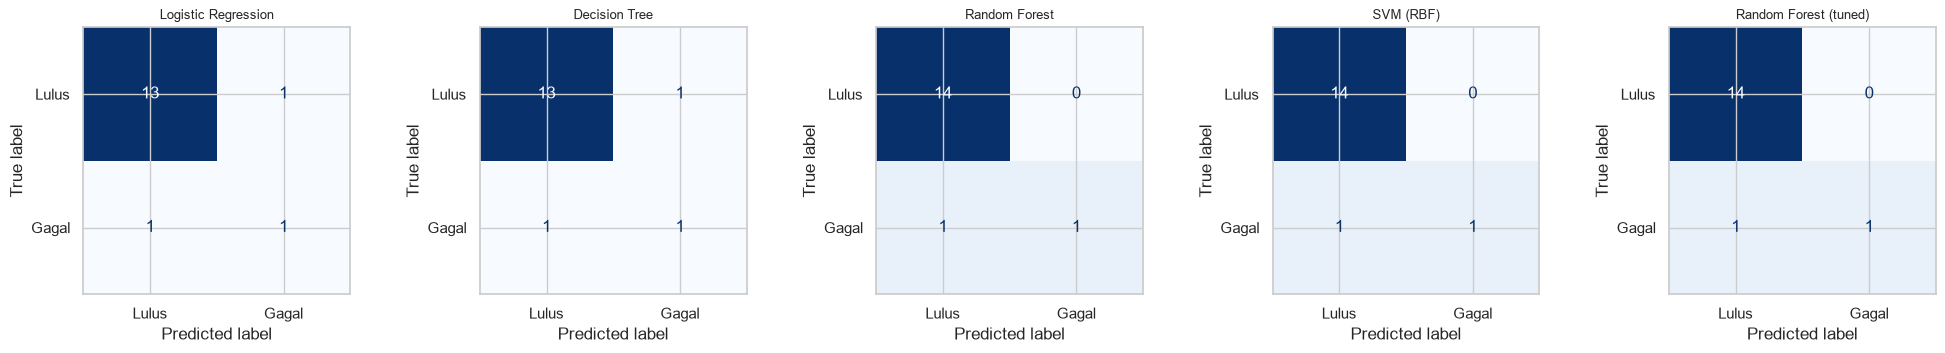

In [48]:
# Confusion matrix semua model
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.6))
for ax, (nama, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Lulus', 'Gagal']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nama, fontsize=9)
plt.tight_layout()
plt.show()


In [49]:
# Laporan lengkap untuk model terbaik
model_terbaik = models[nama_terbaik]
print('Laporan model terbaik:', nama_terbaik)
print(classification_report(y_test, model_terbaik.predict(X_test),
                            target_names=['Lulus (0)', 'Gagal (1)'], zero_division=0))

Laporan model terbaik: Logistic Regression
              precision    recall  f1-score   support

   Lulus (0)       0.93      0.93      0.93        14
   Gagal (1)       0.50      0.50      0.50         2

    accuracy                           0.88        16
   macro avg       0.71      0.71      0.71        16
weighted avg       0.88      0.88      0.88        16



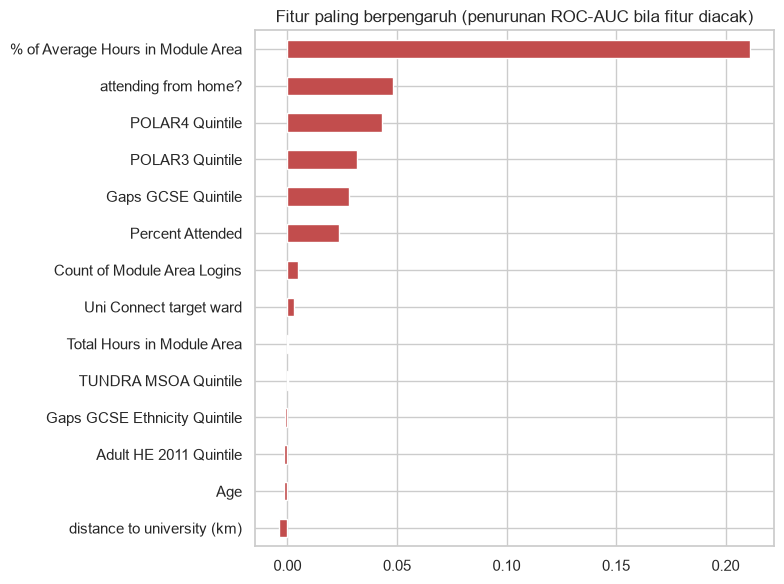

In [50]:
# Permutation importance: seberapa turun kinerja model jika satu fitur diacak?
perm = permutation_importance(model_terbaik, X_train, y_train, scoring='roc_auc',
                              n_repeats=30, random_state=RANDOM_STATE)
penting = pd.Series(perm.importances_mean, index=X_train.columns).sort_values()

penting.plot.barh(figsize=(8, 6), color='#c24d4d')
plt.title('Fitur paling berpengaruh (penurunan ROC-AUC bila fitur diacak)')
plt.tight_layout()
plt.show()

In [51]:
print('5 fitur paling berpengaruh:')
print(penting.sort_values(ascending=False).head(5).round(4))

5 fitur paling berpengaruh:
% of Average Hours in Module Area    0.2114
attending from home?                 0.0482
POLAR4 Quintile                      0.0433
POLAR3 Quintile                      0.0320
Gaps GCSE Quintile                   0.0283
dtype: float64


In [52]:
rng = np.random.default_rng(2025)
jumlah_baru = 5
fitur_asli = [c for c in df.columns if c != LABEL]   # 19 fitur asli

data_baru = {}
for kolom in fitur_asli:
    nilai = df[kolom].dropna()
    nilai_min, nilai_maks = nilai.min(), nilai.max()
    if (nilai % 1 == 0).all():        # fitur bilangan bulat
        data_baru[kolom] = rng.integers(int(nilai_min), int(nilai_maks) + 1, jumlah_baru)
    else:                             # fitur desimal
        data_baru[kolom] = rng.uniform(nilai_min, nilai_maks, jumlah_baru).round(2)
data_baru = pd.DataFrame(data_baru)


In [53]:
# Samakan kolom kehadiran supaya masuk akal (12 pertemuan)
data_baru['Percent Attended'] = (data_baru['# of presence'] / 12 * 100).clip(upper=100).round(2)
data_baru['# of Absence'] = (12 - data_baru['# of presence']).clip(lower=0)
data_baru.index = ['Mahasiswa baru ' + str(i + 1) for i in range(jumlah_baru)]
data_baru

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended
Mahasiswa baru 1,0,40,2,5,1,1,4,2,0,3,0,0,241.20,22,149.48,2.72,11,1,91.67
Mahasiswa baru 2,1,35,1,5,2,2,2,3,1,3,0,1,248.16,257,65.13,3.10,1,11,8.33
Mahasiswa baru 3,1,40,3,4,3,0,1,1,0,5,0,1,88.19,96,80.21,2.65,7,5,58.33
Mahasiswa baru 4,0,38,2,4,2,2,0,0,3,2,0,1,164.26,193,52.86,1.40,6,6,50.00
Mahasiswa baru 5,1,44,3,2,4,5,5,1,0,0,0,1,255.32,210,142.20,5.41,13,0,100.00


In [54]:
# Pembersihan yang sama dengan data latih -> pilih kolom akhir -> prediksi
data_siap = siapkan_data(data_baru)[FITUR_AKHIR]
prediksi = model_terbaik.predict(data_siap)
peluang = model_terbaik.predict_proba(data_siap)

hasil = data_baru[['Percent Attended', 'Count of Module Area Logins', 'Total Hours in Module Area']].copy()
hasil['P(lulus)'] = peluang[:, 0].round(3)
hasil['P(gagal)'] = peluang[:, 1].round(3)
hasil['Prediksi'] = np.where(prediksi == 1, 'GAGAL', 'LULUS')


In [55]:
print('Model:', nama_terbaik)
hasil

Model: Logistic Regression


,Percent Attended,Count of Module Area Logins,Total Hours in Module Area,P(lulus),P(gagal),Prediksi
Mahasiswa baru 1,91.67,22,149.48,1.000,0.000,LULUS
Mahasiswa baru 2,8.33,257,65.13,1.000,0.000,LULUS
Mahasiswa baru 3,58.33,96,80.21,0.989,0.011,LULUS
Mahasiswa baru 4,50.00,193,52.86,0.984,0.016,LULUS
Mahasiswa baru 5,100.00,210,142.20,1.000,0.000,LULUS


In [56]:
# Penjelasan singkat setiap mahasiswa
for nama, baris in hasil.iterrows():
    if baris['Prediksi'] == 'GAGAL':
        p = baris['P(gagal)']
    else:
        p = baris['P(lulus)']
    keyakinan = 'tinggi' if p >= 0.75 else 'sedang/ragu-ragu'
    print(f"- {nama}: diprediksi {baris['Prediksi']} (peluang {p:.2f}, keyakinan {keyakinan}), kehadiran {baris['Percent Attended']:.0f}%")

- Mahasiswa baru 1: diprediksi LULUS (peluang 1.00, keyakinan tinggi), kehadiran 92%
- Mahasiswa baru 2: diprediksi LULUS (peluang 1.00, keyakinan tinggi), kehadiran 8%
- Mahasiswa baru 3: diprediksi LULUS (peluang 0.99, keyakinan tinggi), kehadiran 58%
- Mahasiswa baru 4: diprediksi LULUS (peluang 0.98, keyakinan tinggi), kehadiran 50%
- Mahasiswa baru 5: diprediksi LULUS (peluang 1.00, keyakinan tinggi), kehadiran 100%
